**ASSIGNMENT - SCIENTIFIC COMPUTING LAB**

- CAMBERED AIRFOIL NACA abcd
- Reconstructing smooth airfoil surface

In [181]:
import numpy as np
import matplotlib.pyplot as plt

Using random number generator in numpy to choose each the maximum camber, the location of maximum camber and the the percentage of thickness to chord.

In [182]:
np.random.seed()
m = np.random.uniform(0.01, 0.09) 
p = np.random.uniform(0.10, 0.50) 
t = np.random.uniform(0.05, 0.30)

Random parameters for NACA abcd: 
- a (m): Max camber (1% to 9% of chord -> 0.01 to 0.09) 
- b (p): Location of max camber (10% to 50% of chord -> 0.1 to 0.5) 
- cd (t): Thickness-to-chord ratio (5% to 30% -> 0.05 to 0.30)

In [183]:
print(f"Generated NACA Airfoil Parameters:") 
print(f" - Max Camber (m): {m:.4f} ") 
print(f" - Max Camber Position (p): {p:.4f} ") 
print(f" - Max Thickness (t): {t:.4f} ")

def naca4_airfoil(x, m, p, t): 
    yt = 5 * t * (0.2969 * np.sqrt(x) - 0.1260 * x - 0.3516 * x**2 + 0.2843 * x**3 - 0.1015 * x**4)
    yc = np.where(x < p, (m / p**2) * (2 * p * x - x**2), (m / (1 - p)**2) * ((1 - 2 * p) + 2 * p * x - x**2))
    dyc_dx = np.where(x < p, (2 * m / p**2) * (p - x), (2 * m / (1 - p)**2) * (p - x))

    theta = np.arctan(dyc_dx)

    xu = x - yt * np.sin(theta) 
    yu = yc + yt * np.cos(theta) 
    xl = x + yt * np.sin(theta) 
    yl = yc - yt * np.cos(theta) 

    return xu,yu,xl,yl

x = np.linspace(0, 1, 1000)
xu_true, yu_true, xl_true, yl_true = naca4_airfoil(x, m, p, t)

Generated NACA Airfoil Parameters:
 - Max Camber (m): 0.0811 
 - Max Camber Position (p): 0.4521 
 - Max Thickness (t): 0.2057 


**Using the function 'Lagrng()' to reconstruct the same Airfoil**

In [184]:
def Lagrng(x_nodes, y_nodes, x_eval):
    N = len(x_nodes) 
    y_interp = np.zeros_like(x_eval)
    for i in range(N):
        L_i = np.ones_like(x_eval)
        for j in range(N): 
            if i != j: 
                L_i *= (x_eval - x_nodes[j]) / (x_nodes[i] - x_nodes[j]) 
        y_interp += y_nodes[i] * L_i 
    return y_interp
N = 10    
x_uniform = np.linspace(0, 1, N)
xu_pts, yu_pts, xl_pts, yl_pts = naca4_airfoil(x_uniform, m, p, t)

yu_lagrange = Lagrng(xu_pts, yu_pts, xu_true) 
yl_lagrange = Lagrng(xl_pts, yl_pts, xl_true)

Plotting both true and Lagrange interpolation Airfoil in the same graph for visual comparison

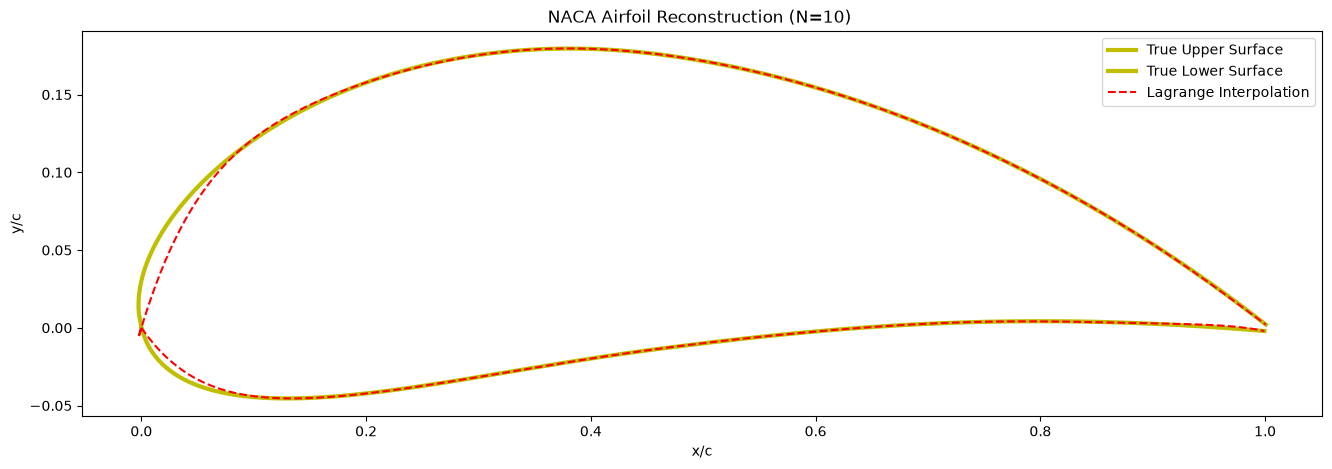

In [185]:
plt.figure(figsize=(16,5)) 
plt.plot(xu_true, yu_true, 'y-', label='True Upper Surface', linewidth=3)
plt.plot(xl_true, yl_true, 'y-', label='True Lower Surface', linewidth=3)
plt.plot(xu_true, yu_lagrange, 'r--', label='Lagrange Interpolation') 
plt.plot(xl_true, yl_lagrange, 'r--') 
plt.title(f'NACA Airfoil Reconstruction (N=10) ') 
plt.xlabel('x/c') 
plt.ylabel('y/c')
plt.legend() 
plt.show()

**Reconstructing airfoil using cubic spline interpolation**

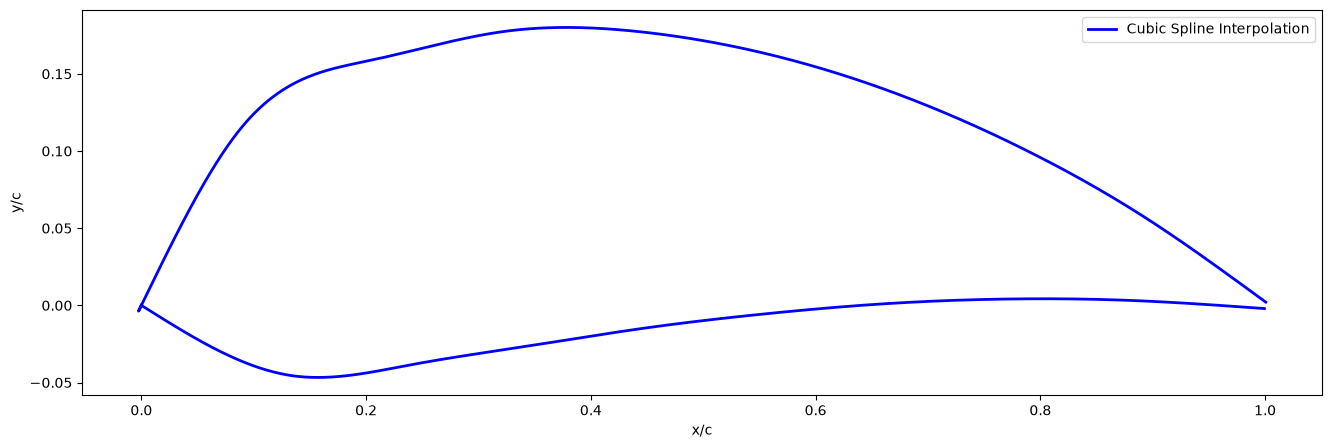

In [186]:
def cubic_spline_interp(x_nodes, y_nodes, x_eval):
    n = len(x_nodes) - 1
    h = np.diff(x_nodes)
    A = np.zeros((n + 1, n + 1))
    b = np.zeros(n + 1) 

    A[0, 0] = 1.0
    A[n, n] = 1.0

    for i in range(1, n): 
        A[i, i - 1] = h[i - 1] 
        A[i, i] = 2 * (h[i - 1] + h[i]) 
        A[i, i + 1] = h[i] 
        b[i] = 3 * ((y_nodes[i + 1] - y_nodes[i]) / h[i] - (y_nodes[i] - y_nodes[i - 1]) / h[i - 1]) 

    c = np.linalg.solve(A, b)

    b_coeff = np.zeros(n) 
    d_coeff = np.zeros(n) 
    a_coeff = y_nodes[:-1] 

    for i in range(n): 
        b_coeff[i] = (y_nodes[i + 1] - y_nodes[i]) / h[i] - h[i] * (2 * c[i] + c[i + 1]) / 3 
        d_coeff[i] = (c[i + 1] - c[i]) / (3 * h[i]) 
         
    c_coeff = c[:-1]

    y_eval = np.zeros_like(x_eval) 
    for j, x_val in enumerate(x_eval):  
        if x_val <= x_nodes[0]: 
            idx = 0 
        elif x_val >= x_nodes[-1]: 
            idx = n - 1 
        else: 
            idx = np.searchsorted(x_nodes, x_val) - 1 
             
        dx = x_val - x_nodes[idx] 
        y_eval[j] = a_coeff[idx] + b_coeff[idx] * dx + c_coeff[idx] * (dx**2) + d_coeff[idx] * (dx**3) 
         
    return y_eval 

yu_spline = cubic_spline_interp(xu_pts, yu_pts, xu_true) 
yl_spline = cubic_spline_interp(xl_pts, yl_pts, xl_true)
plt.figure(figsize=(16,5))
plt.plot(xu_true, yu_spline, 'b-', label='Cubic Spline Interpolation', linewidth=2)
plt.plot(xl_true, yl_spline, 'b-', linewidth=2)
plt.xlabel('x/c') 
plt.ylabel('y/c')
plt.legend() 
plt.show()


**Quantify the error (max, RMS) between the true and reconstructed results**

In [187]:
def calc_errors(true, pred): 
    err = np.abs(true - pred) 
    max_err = np.max(err) 
    rms_err = np.sqrt(np.mean(err**2)) 
    return max_err, rms_err 
err_max_lag_u, err_rms_lag_u = calc_errors(yu_true, yu_lagrange) 
err_max_lag_l, err_rms_lag_l = calc_errors(yl_true, yl_lagrange) 
err_max_spl_u, err_rms_spl_u = calc_errors(yu_true, yu_spline) 
err_max_spl_l, err_rms_spl_l = calc_errors(yl_true, yl_spline)

print(f"Lagrange Upper Surface  -> Max Error: {err_max_lag_u:.6e}, RMS Error: {err_rms_lag_u:.6e}") 
print(f"Lagrange Lower Surface  -> Max Error: {err_max_lag_l:.6e}, RMS Error: {err_rms_lag_l:.6e}") 
print(f"Cubic Spline Upper Surface -> Max Error: {err_max_spl_u:.6e}, RMS Error: {err_rms_spl_u:.6e}") 
print(f"Cubic Spline Lower Surface -> Max Error: {err_max_spl_l:.6e}, RMS Error: {err_rms_spl_l:.6e}") 


Lagrange Upper Surface  -> Max Error: 3.090801e-02, RMS Error: 5.989088e-03
Lagrange Lower Surface  -> Max Error: 7.005938e-03, RMS Error: 1.189143e-03
Cubic Spline Upper Surface -> Max Error: 3.533643e-02, RMS Error: 8.306199e-03
Cubic Spline Lower Surface -> Max Error: 1.632029e-02, RMS Error: 3.628175e-03


**Improving Reconstruction Results via Point Spacing**

- High-degree polynomial interpolation over uniformly spaced points often suffers from high-frequency 
oscilations near boundaries.
- Because airfoils exhibit high curvature near the leading edge (x≈0), uniform sampling yields high interpolation errors at the nose.
- Instead of linearly spacing nodes with np.linspace, sample nodes densely near the leading and trailing edges using Chebyshev-Gauss-Lobatto nodes: 
x_i =21 (1−cos(N−1iπ )),i=0,1,…,N−1 
- Place a higher concentration of sample points in regions where the second derivative ∣y′′(x)∣ is large (leading edge,camber locations)